In [2]:
import numpy as np
import matplotlib.pyplot as plt

# Part b

q_50 is [0.125 0.    0.75  0.    0.125]
q_51 is [0.  0.5 0.  0.5 0. ]


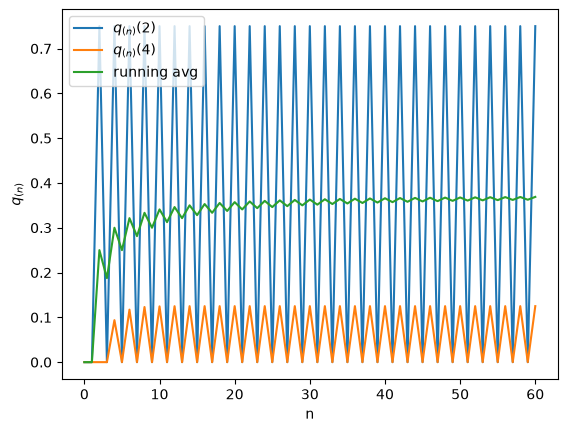

In [3]:
q_0 = [1, 0, 0, 0, 0]
p = np.array([[0, 1, 0, 0, 0],
             [1/4, 0, 3/4, 0, 0],
             [0, 1/2, 0, 1/2, 0],
             [0, 0, 3/4, 0, 1/4],
             [0, 0, 0, 1, 0]])

qn = []
for i in range(0, 61):
    p_pow = np.linalg.matrix_power(p, i)
    qi = q_0 @ p_pow
    qn.append(qi)
qn = np.array(qn)

print(f"q_50 is {qn[50]}")
print(f"q_51 is {qn[51]}")

plt.plot(range(0,61), qn[:,2], label = r"$q_{(n)}(2)$")
plt.plot(range(0,61), qn[:,4], label = r"$q_{(n)}(4)$")
plt.plot(np.cumsum(qn[:, 2]) / np.arange(1, 62), label = "running avg")
plt.xlabel("n")
plt.ylabel(r"$q_{(n)}$")
plt.legend()

# Part c

In [4]:
a, b = 0.3, 0.1
P = np.zeros((5,5))
for k in range(5):
    if k < 4: P[k,k+1] = a*(4-k)/4
    if k > 0: P[k,k-1] = b*k/4
    P[k,k] = 1 - P[k].sum()

A = P.T - np.eye(5)
A[-1, :] = 1
c = np.zeros(5); c[-1] = 1
pi = np.linalg.solve(A, c)

In [5]:
part_a_pi = np.array([(1/4) ** 4, (3/4) * ((1/4) ** 3) * 4, ((3/4) ** 2) * ((1/4) ** 2) * 6, ((3/4) ** 3) * ((1/4) ** 1) * 4, ((3/4) ** 4)])
np.isclose(part_a_pi, pi)

array([ True,  True,  True,  True,  True])

a=1, b=1: q_50 is [0.125 0.    0.75  0.    0.125]
a=1, b=1: q_51 is [0.  0.5 0.  0.5 0. ]
a=0.3, b=0.1: q_50 is [0.00415085 0.04881971 0.21527993 0.42183893 0.30991058]
a=0.3, b=0.1: q_51 is [0.00412609 0.04862403 0.2148463  0.42184614 0.31055744]


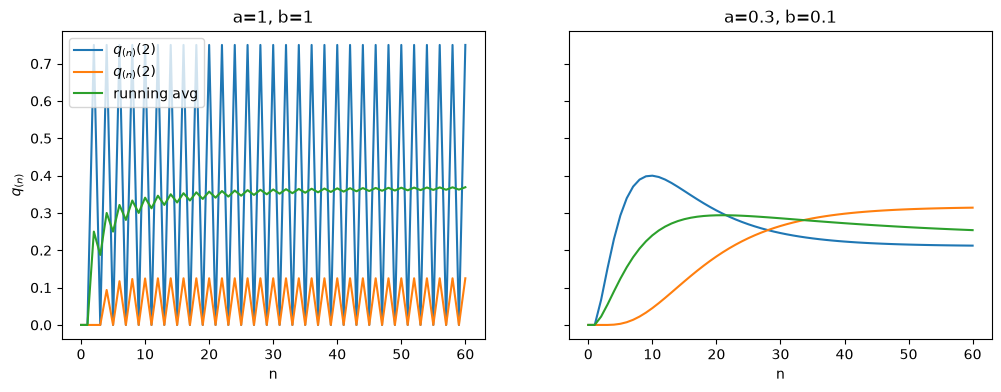

In [6]:
q_0 = [1, 0, 0, 0, 0]

p1 = np.array([[0, 1, 0, 0, 0],
               [1/4, 0, 3/4, 0, 0],
               [0, 1/2, 0, 1/2, 0],
               [0, 0, 3/4, 0, 1/4],
               [0, 0, 0, 1, 0]])

p2 = np.array([[0.7, 0.3, 0, 0, 0],
               [0.025, 0.75, 0.225, 0, 0],
               [0, 0.05, 0.8, 0.15, 0],
               [0, 0, 0.075, 0.85, 0.075],
               [0, 0, 0, 0.1, 0.9]])

qn1 = np.array([q_0 @ np.linalg.matrix_power(p1, i) for i in range(0, 61)])
qn2 = np.array([q_0 @ np.linalg.matrix_power(p2, i) for i in range(0, 61)])

print(f"a=1, b=1: q_50 is {qn1[50]}")
print(f"a=1, b=1: q_51 is {qn1[51]}")
print(f"a=0.3, b=0.1: q_50 is {qn2[50]}")
print(f"a=0.3, b=0.1: q_51 is {qn2[51]}")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4), sharey=True)

ax1.plot(range(0,61), qn1[:,2], label = r"$q_{(n)}(2)$")
ax1.plot(range(0,61), qn1[:,4], label = r"$q_{(n)}(2)$")
ax1.plot(np.cumsum(qn1[:, 2]) / np.arange(1, 62), label = "running avg")
ax1.legend()
ax1.set_title("a=1, b=1")
ax1.set_ylabel(r"$q_{(n)}$")
ax1.set_xlabel("n")

ax2.plot(range(0,61), qn2[:,2])
ax2.plot(range(0,61), qn2[:,4])
ax2.plot(np.cumsum(qn2[:, 2]) / np.arange(1, 62))
ax2.set_xlabel("n")
ax2.set_title("a=0.3, b=0.1")

fig.savefig("/Users/viro3403/Library/CloudStorage/OneDrive-UCB-O365/Desktop/Markov/hw5p1.png")

In [19]:
qn2 = np.array([q_0 @ np.linalg.matrix_power(p2, i) for i in range(0, 200)])
for i in range(len(qn2)):
    row = qn2[i,:]
    if max(np.abs(row - pi)) < 10 ** (-6):
        print(i)
        break

134


In [18]:
eigvals = np.linalg.eigvals(p2)
mods = np.sort(np.abs(eigvals))[::-1] 
second_largest = mods[1]
print(second_largest)

0.9000000000000006
